<a href="https://colab.research.google.com/github/yordi-14/StatQueen/blob/main/Bisection_Method_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bisection Method
**Numerical Analysis · Lab · Final version**

**Problem.** Solve $f(x)=0$ on an interval $[a,b]$.

**Idea.** If $f(a)$ and $f(b)$ have opposite signs, there is a root between $a$ and $b$.
1. Find the midpoint $c=\dfrac{a+b}{2}$.
2. If $f(a)f(c)<0$, the root is in $[a,c]$, so set $b=c$. Otherwise set $a=c$.
3. Repeat until the interval is small.

## Step 1: Import

In [ ]:
import math

## Step 2: Important notation (read this before the code)

### A. Math symbols in Python
| We write | Python | Example | Result |
|---|---|---|---|
| $x^2$, $x^3$ | `x**2`, `x**3` | `3**2` | 9 |
| $a\times b$ | `a * b` | `2 * 5` | 10 |
| $\dfrac{a}{b}$ | `a / b` | `7 / 2` | 3.5 |
| $\lvert x\rvert$ | `abs(x)` | `abs(-4)` | 4 |
| $\sqrt{x}$ | `math.sqrt(x)` | `math.sqrt(2)` | 1.41421 |
| $e^{x}$ | `math.exp(x)` | `math.exp(1)` | 2.71828 |
| $\ln x$ | `math.log(x)` | `math.log(10)` | 2.30259 |
| $\cos x$, $\sin x$ | `math.cos(x)`, `math.sin(x)` | `math.cos(0)` | 1.0 |
| $\pi$ | `math.pi` | | 3.14159 |
| $1.5\times10^{-4}$ | `1.5e-4` | `tol = 1e-6` | 0.000001 |

### B. Symbols used in the method
| Symbol | Meaning | Example |
|---|---|---|
| `=` | **store** a value in a name | `c = (a + b) / 2` |
| `==` | **ask** if two values are equal | `f(c) == 0` |
| `<` `>` `<=` `>=` `!=` | smaller, larger, at most, at least, not equal | `f(a) * f(c) < 0` |
| `and`, `or` | both true, at least one true | `a < c and c < b` |
| `def f(x):` | define a function; `return` gives back the answer | `return x**2 - 2` |
| `while condition:` | repeat **while** the condition is true | `while (b - a) / 2 > tol:` |
| `for step in range(1, 5):` | repeat for step = 1, 2, 3, 4 (5 is not included) | |
| `if ... :` / `else:` | choose between two cases | |
| `[ ]` | a **list** of values; `table.append(row)` adds one row | `row = [1, 1.0, 2.0]` |
| `row[0]`, `row[1]` | one item of a list (counting starts at **0**) | `row[0]` is the first |
| `#` | a comment: Python ignores it | `# midpoint` |
| `\n` | start a new line inside text | `print("a\nb")` |
| `"-" * 20` | repeat a text 20 times (to draw a line) | `--------------------` |

### C. What does **f** mean? (three different meanings!)
| Where you see it | Meaning | Example |
|---|---|---|
| `f"..."` (before the quote) | **f-string** = *formatted string*: text where `{ }` is replaced by a value | `f"x = {x}"` prints `x = 3.14` |
| `.6f` (inside `{ }`, after the colon) | **f**ixed-point number: show the value with a fixed number of decimals | `f"{x:.6f}"` gives `3.141593` |
| `f(x)`, `f(a)`, `f(c)` | the **function** $f$ of our equation $f(x)=0$ (a name we choose; it could be `g` or `h`) | `def f(x): return x**2 - 2` |

So in `f"{f(c):>12.2e}"` the first `f` makes an f-string, `f(c)` is our function evaluated at $c$, and the `e` shows the result in scientific notation.

### D. Format codes for printing: `f"{value:>12.6f}"`
The text after the colon `:` tells Python **how to show** the value. The order is:
$$\texttt{\{value : [align][width][.precision][type]\}}$$

| Part | Code | Meaning |
|---|---|---|
| **align** | `>` | right (numbers: best for tables) |
| | `<` | left (names) |
| | `^` | centre |
| **width** | `12` | the column uses 12 characters |
| **.precision** | `.6` | 6 digits after the point (with `f` and `e`) |
| **type** | `d` | whole number (**d**ecimal integer): `7` |
| | `f` | fixed decimals (**f**loat): `3.141593` |
| | `e` | scientific notation (**e**xponent): `3.14e+00` |
| | `g` | general: Python chooses `f` or `e` for you |
| | `s` | text (**s**tring), the default for words |
| | `%` | percentage: `0.25` becomes `25.000000%` |
| **extras** | `+` | always show the sign: `+3.14` |
| | `0` | fill with zeros: `0007` |
| | `,` | thousands separator: `1,234,567` |

Look at each code at work (the square brackets `[ ]` show the edges of the column):

In [ ]:
x = 3.14159265358979
n = 7

print(f"[{x}]")              # no format: Python shows everything
print(f"[{x:>12.6f}]")       # right aligned, width 12, 6 decimals
print(f"[{x:<12.3f}]")       # left aligned, width 12, 3 decimals
print(f"[{x:^12.3f}]")       # centred
print(f"[{x:>12.2e}]")       # scientific notation, 2 decimals
print(f"[{x:>12.4g}]")       # general format, 4 significant digits
print(f"[{x:+.3f}]")         # with sign
print(f"[{n:>5d}]")          # whole number, width 5
print(f"[{n:05d}]")          # whole number filled with zeros
print(f"[{1234567:,d}]")     # thousands separator
print(f"[{0.25:.1%}]")       # percentage
print(f"[{'step':>8}]")      # text, right aligned

[3.14159265358979]
[    3.141593]
[3.142       ]
[   3.142    ]
[    3.14e+00]
[       3.142]
[+3.142]
[    7]
[00007]
[1,234,567]
[25.0%]
[    step]


**Small numbers.** A number like `0.00000123` is hard to read with `f`. In numerical analysis we use `e`:
`f"{0.00000123:.2e}"` prints `1.23e-06`, which means $1.23\times10^{-6}$. We use `e` for **errors** and values $f(c)$ close to 0.

### E. A small table, built in 3 steps
(1) print the **header**, (2) print a **line**, (3) print one **row** for each step.

In [ ]:
print(f"{'step':>5} {'a':>10} {'b':>10}")        # 1. header  (names in quotes, same widths as the rows)
print("-" * 27)                                    # 2. line (27 = 5 + 1 + 10 + 1 + 10)

for step in range(1, 4):                           # 3. rows
    a = step * 1.5
    b = step * 2.25
    print(f"{step:>5d} {a:>10.4f} {b:>10.4f}")

 step          a          b
---------------------------
    1     1.5000     2.2500
    2     3.0000     4.5000
    3     4.5000     6.7500


**Tip.** The numbers in the header and in the rows must use the **same widths**, otherwise the columns do not line up.

## Step 3: Write the functions
### 3a. `print_table`: prints the steps as a table
We write the printing **once**, so every version of the method can use it.

In [1]:
COLUMNS = ["step", "a", "b", "c", "f(c)", "error bound"]

def print_table(table):
    # header, line, one row for each step, line
    print(f"{'step':>5} {'a':>12} {'b':>12} {'c':>12} {'f(c)':>12} {'error bound':>12}")
    print("-" * 70)
    for row in table:
        print(f"{row[0]:>5d} {row[1]:>12.6f} {row[2]:>12.6f} {row[3]:>12.6f} {row[4]:>12.2e} {row[5]:>12.2e}")
    print("-" * 70)

### 3b. `bisection` with a `while` loop
The loop repeats **while** the interval is still too big. It collects one row per step in `table`.

In [2]:
def bisection(f, a, b, tol=0.0001, show=True):
    # f   : the function we want to solve, f(x) = 0
    # a, b: the interval [a, b]
    # tol : how accurate we want the answer
    # show: True = print the table

    # check the sign change
    if f(a) * f(b) > 0:
        print("Error: f(a) and f(b) must have opposite signs")
        return None, []

    table = []                                    # we store one row for each step
    step = 0
    c = (a + b) / 2                               # (in case the interval is already small)
    while (b - a) / 2 > tol:                      # repeat WHILE the interval is too big
        step = step + 1
        c = (a + b) / 2                           # midpoint
        table.append([step, a, b, c, f(c), (b - a) / 2])   # save this row

        if f(c) == 0:                             # c is the exact root
            break
        if f(a) * f(c) < 0:                       # root in [a, c]
            b = c
        else:                                     # root in [c, b]
            a = c

    root = c if f(c) == 0 else (a + b) / 2

    if show:
        print_table(table)
        print("Root =", root, "  (found in", step, "steps)\n")

    return root, table

## Step 4: Solve Example 1
$x^3+4x^2-10=0$ on $[1,2]$

In [3]:
def f1(x):
    return x**3 + 4*x**2 - 10

root, table = bisection(f1, 1, 2)

 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     1.000000     2.000000     1.500000     2.38e+00     5.00e-01
    2     1.000000     1.500000     1.250000    -1.80e+00     2.50e-01
    3     1.250000     1.500000     1.375000     1.62e-01     1.25e-01
    4     1.250000     1.375000     1.312500    -8.48e-01     6.25e-02
    5     1.312500     1.375000     1.343750    -3.51e-01     3.12e-02
    6     1.343750     1.375000     1.359375    -9.64e-02     1.56e-02
    7     1.359375     1.375000     1.367188     3.24e-02     7.81e-03
    8     1.359375     1.367188     1.363281    -3.21e-02     3.91e-03
    9     1.363281     1.367188     1.365234     7.20e-05     1.95e-03
   10     1.363281     1.365234     1.364258    -1.60e-02     9.77e-04
   11     1.364258     1.365234     1.364746    -7.99e-03     4.88e-04
   12     1.364746     1.365234     1.364990    -3.96e-03     2.44e-04
   13 

## Step 5: Solve more examples
We only change the function and the interval, then call `bisection` again.

In [ ]:
# Example 2:  cos(x) - x = 0  on [0, 1]
def f2(x):
    return math.cos(x) - x

root, table = bisection(f2, 0, 1)

 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     0.000000     1.000000     0.500000     3.78e-01     5.00e-01
    2     0.500000     1.000000     0.750000    -1.83e-02     2.50e-01
    3     0.500000     0.750000     0.625000     1.86e-01     1.25e-01
    4     0.625000     0.750000     0.687500     8.53e-02     6.25e-02
    5     0.687500     0.750000     0.718750     3.39e-02     3.12e-02
    6     0.718750     0.750000     0.734375     7.87e-03     1.56e-02
    7     0.734375     0.750000     0.742188    -5.20e-03     7.81e-03
    8     0.734375     0.742188     0.738281     1.35e-03     3.91e-03
    9     0.738281     0.742188     0.740234    -1.92e-03     1.95e-03
   10     0.738281     0.740234     0.739258    -2.89e-04     9.77e-04
   11     0.738281     0.739258     0.738770     5.28e-04     4.88e-04
   12     0.738770     0.739258     0.739014     1.20e-04     2.44e-04
   13 

In [ ]:
# Example 3:  x^2 - 2 = 0  on [1, 2]   (the answer is the square root of 2)
def f3(x):
    return x**2 - 2

root, table = bisection(f3, 1, 2)

 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     1.000000     2.000000     1.500000     2.50e-01     5.00e-01
    2     1.000000     1.500000     1.250000    -4.38e-01     2.50e-01
    3     1.250000     1.500000     1.375000    -1.09e-01     1.25e-01
    4     1.375000     1.500000     1.437500     6.64e-02     6.25e-02
    5     1.375000     1.437500     1.406250    -2.25e-02     3.12e-02
    6     1.406250     1.437500     1.421875     2.17e-02     1.56e-02
    7     1.406250     1.421875     1.414062    -4.27e-04     7.81e-03
    8     1.414062     1.421875     1.417969     1.06e-02     3.91e-03
    9     1.414062     1.417969     1.416016     5.10e-03     1.95e-03
   10     1.414062     1.416016     1.415039     2.34e-03     9.77e-04
   11     1.414062     1.415039     1.414551     9.54e-04     4.88e-04
   12     1.414062     1.414551     1.414307     2.63e-04     2.44e-04
   13 

In [ ]:
# Example 4:  x^3 - x - 2 = 0  on [1, 2]
def f4(x):
    return x**3 - x - 2

root, table = bisection(f4, 1, 2)

 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     1.000000     2.000000     1.500000    -1.25e-01     5.00e-01
    2     1.500000     2.000000     1.750000     1.61e+00     2.50e-01
    3     1.500000     1.750000     1.625000     6.66e-01     1.25e-01
    4     1.500000     1.625000     1.562500     2.52e-01     6.25e-02
    5     1.500000     1.562500     1.531250     5.91e-02     3.12e-02
    6     1.500000     1.531250     1.515625    -3.41e-02     1.56e-02
    7     1.515625     1.531250     1.523438     1.23e-02     7.81e-03
    8     1.515625     1.523438     1.519531    -1.10e-02     3.91e-03
    9     1.519531     1.523438     1.521484     6.22e-04     1.95e-03
   10     1.519531     1.521484     1.520508    -5.18e-03     9.77e-04
   11     1.520508     1.521484     1.520996    -2.28e-03     4.88e-04
   12     1.520996     1.521484     1.521240    -8.29e-04     2.44e-04
   13 

In [ ]:
# Example 5:  e^x - 3x = 0  on [0, 1]
def f5(x):
    return math.exp(x) - 3*x

root, table = bisection(f5, 0, 1)

 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     0.000000     1.000000     0.500000     1.49e-01     5.00e-01
    2     0.500000     1.000000     0.750000    -1.33e-01     2.50e-01
    3     0.500000     0.750000     0.625000    -6.75e-03     1.25e-01
    4     0.500000     0.625000     0.562500     6.76e-02     6.25e-02
    5     0.562500     0.625000     0.593750     2.95e-02     3.12e-02
    6     0.593750     0.625000     0.609375     1.12e-02     1.56e-02
    7     0.609375     0.625000     0.617188     2.14e-03     7.81e-03
    8     0.617188     0.625000     0.621094    -2.32e-03     3.91e-03
    9     0.617188     0.621094     0.619141    -9.07e-05     1.95e-03
   10     0.617188     0.619141     0.618164     1.03e-03     9.77e-04
   11     0.618164     0.619141     0.618652     4.68e-04     4.88e-04
   12     0.618652     0.619141     0.618896     1.88e-04     2.44e-04
   13 

In [ ]:
# Example 6:  a wrong interval (no sign change)
bisection(f1, 2, 3)

Error: f(a) and f(b) must have opposite signs


(None, [])

## Step 6 (optional): The same table with pandas
The function also **returns** the table (a list of rows). With `pandas` we can turn it into a nice table in one line.

In [ ]:
import pandas as pd

root, table = bisection(f1, 1, 2, show=False)      # show=False: do not print, just return the rows
df = pd.DataFrame(table, columns=COLUMNS)
df

,step,a,b,c,f(c),error bound
0,1,1.000000,2.000000,1.500000,2.375000,0.500000
1,2,1.000000,1.500000,1.250000,-1.796875,0.250000
2,3,1.250000,1.500000,1.375000,0.162109,0.125000
3,4,1.250000,1.375000,1.312500,-0.848389,0.062500
4,5,1.312500,1.375000,1.343750,-0.350983,0.031250
5,6,1.343750,1.375000,1.359375,-0.096409,0.015625
6,7,1.359375,1.375000,1.367188,0.032356,0.007812
7,8,1.359375,1.367188,1.363281,-0.032150,0.003906
8,9,1.363281,1.367188,1.365234,0.000072,0.001953
9,10,1.363281,1.365234,1.364258,-0.016047,0.000977


## Step 7 (optional): Plot the error at each step

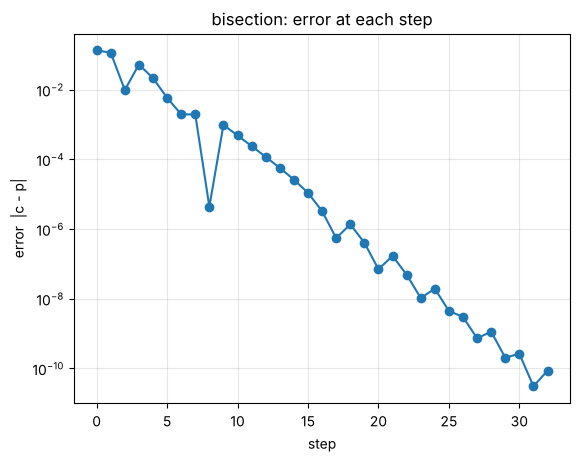

In [ ]:
import matplotlib.pyplot as plt

p = 1.365230013414097                           # the true root of f1
root, table = bisection(f1, 1, 2, tol=1e-10, show=False)

errors = [abs(row[3] - p) for row in table]     # error |c - p| at each step
plt.semilogy(errors, "o-")                      # log scale on the y-axis
plt.xlabel("step"); plt.ylabel("error  |c - p|"); plt.grid(alpha=0.3)
plt.title("bisection: error at each step"); plt.show()

## Step 8: The same method with a `for` loop
A `while` loop repeats **until** the interval is small. A `for` loop repeats a **fixed number** of times, so we first compute how many steps we need.

After $n$ steps the error is at most $\dfrac{b-a}{2^n}$. We want this $\le \text{tol}$:

$$\frac{b-a}{2^n}\le\text{tol}\quad\Longleftrightarrow\quad n\ \ge\ \log_2\frac{b-a}{\text{tol}}$$

In Python: `n = math.ceil(math.log2((b - a) / tol))`. Here `math.ceil` rounds **up** to a whole number (e.g. $13.29 \to 14$).

In [ ]:
def bisection_for(f, a, b, tol=0.0001, show=True):
    # f   : the function we want to solve, f(x) = 0
    # a, b: the interval [a, b]
    # tol : how accurate we want the answer
    # show: True = print the table

    # check the sign change
    if f(a) * f(b) > 0:
        print("Error: f(a) and f(b) must have opposite signs")
        return None, []

    # number of steps we need:  n >= log2((b - a) / tol)
    n = math.ceil(math.log2((b - a) / tol))

    table = []                                    # one row for each step
    for step in range(1, n + 1):                  # repeat EXACTLY n times
        c = (a + b) / 2                           # midpoint
        table.append([step, a, b, c, f(c), (b - a) / 2])   # save this row

        if f(c) == 0:                             # c is the exact root
            break
        if f(a) * f(c) < 0:                       # root in [a, c]
            b = c
        else:                                     # root in [c, b]
            a = c

    if show:
        print(f"Number of steps needed: n = {n}")
        print_table(table)
        print("Root =", c, "  (after", len(table), "steps)\n")

    return c, table

Use it exactly like `bisection`:

In [ ]:
root, table = bisection_for(f1, 1, 2)

Number of steps needed: n = 14
 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     1.000000     2.000000     1.500000     2.38e+00     5.00e-01
    2     1.000000     1.500000     1.250000    -1.80e+00     2.50e-01
    3     1.250000     1.500000     1.375000     1.62e-01     1.25e-01
    4     1.250000     1.375000     1.312500    -8.48e-01     6.25e-02
    5     1.312500     1.375000     1.343750    -3.51e-01     3.12e-02
    6     1.343750     1.375000     1.359375    -9.64e-02     1.56e-02
    7     1.359375     1.375000     1.367188     3.24e-02     7.81e-03
    8     1.359375     1.367188     1.363281    -3.21e-02     3.91e-03
    9     1.363281     1.367188     1.365234     7.20e-05     1.95e-03
   10     1.363281     1.365234     1.364258    -1.60e-02     9.77e-04
   11     1.364258     1.365234     1.364746    -7.99e-03     4.88e-04
   12     1.364746     1.365234     1.364990  

In [ ]:
root, table = bisection_for(f2, 0, 1)            # cos(x) - x = 0  on [0, 1]

Number of steps needed: n = 14
 step            a            b            c         f(c)  error bound
----------------------------------------------------------------------
    1     0.000000     1.000000     0.500000     3.78e-01     5.00e-01
    2     0.500000     1.000000     0.750000    -1.83e-02     2.50e-01
    3     0.500000     0.750000     0.625000     1.86e-01     1.25e-01
    4     0.625000     0.750000     0.687500     8.53e-02     6.25e-02
    5     0.687500     0.750000     0.718750     3.39e-02     3.12e-02
    6     0.718750     0.750000     0.734375     7.87e-03     1.56e-02
    7     0.734375     0.750000     0.742188    -5.20e-03     7.81e-03
    8     0.734375     0.742188     0.738281     1.35e-03     3.91e-03
    9     0.738281     0.742188     0.740234    -1.92e-03     1.95e-03
   10     0.738281     0.740234     0.739258    -2.89e-04     9.77e-04
   11     0.738281     0.739258     0.738770     5.28e-04     4.88e-04
   12     0.738770     0.739258     0.739014  

**`while` or `for`?**

| | `while` loop | `for` loop |
|---|---|---|
| Repeats | **until** the interval is small enough | a **fixed** number of times $n$ |
| Number of steps | found while running | computed **before** we start |
| Root returned | midpoint of the last interval | the last midpoint $c_n$ |
| Works for | bisection and other methods | bisection only (we know $n$ in advance only for bisection) |

Both give the root with error at most `tol`. The `for` loop may do one step more, because it returns $c_n$ instead of the midpoint of the final interval.

## Your turn
1. Write your own function `f(x)` and call `bisection`: $x^3-2x-5=0$ on $[2,3]$ (answer about $2.0946$).
2. Change the table: print the columns with **8** decimals instead of 6.
3. Add a new column to the table: the **relative change** $|c_k - c_{k-1}|$.

In [ ]:
# write your code here